# The rotation axis during a ramp load

A hemispheric load (melt of Northern Hemisphere ice) is ramped up linearly from rest, then held. The arrow is the rotation axis
$\bO+\boldsymbol\omega$ in the Earth-fixed frame, drawn on a globe with the model's coastlines; the dashed arrow is the static (AA24) axis.
The real tilt is a few tens of milliarcseconds, so the tilt angle is multiplied by a large factor. Both the drift and the wobble are
magnified by the same factor, so the shape of the motion is exact.

The dynamic axis lags the static one at right angles to the drift, and circles it in a free wobble once the ramp ends (note §5.4).
Both effects scale with the drift rate. Over the 20-year ramp of `examples_dynamic.ipynb` they are only about 1% of the tilt, so
here the ramp lasts 3 years (set `ramp_years` to change it).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

import solver_dynamic as sd
import examples_dynamic_helper as eh

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#=======================================================================
# Parameters
#=======================================================================

lmax = 32
rtol = 1e-10
year_days = 365.25

# Load: fraction of Northern Hemisphere ice, ramp duration and run length (years)
nh_fraction = 1e-3
ramp_years = 3.0
run_years = 6.0

# Time step (days), and every frame_stride-th step is a frame
dt_days = 7.0
frame_stride = 2
frames_per_second = 15

# Tilt of the final static axis in the drawing (degrees)
final_tilt_degrees = 30.0

gif_path = "animations/rotation_axis_ramp.gif"

In [3]:
#=======================================================================
# Earth model, the ramp load and the run
#=======================================================================

state = sd.make_state(lmax)
model = state.model
constants = sd.rotation_constants(model)
day = float(sd.days_to_model_time(1.0, constants))
year = year_days * day

nh_load = state.northern_hemisphere_load(fraction=nh_fraction)
ramp = sd.LinearRamp(ramp_years * year)
ramp_nh = sd.SeparableLoad([(nh_load, ramp)])
static_nh = sd.equilibrium_rotation(state, constants, nh_load, rtol=1e-12)

rhs = sd.forward_rhs(state, constants, ramp_nh, rtol=rtol)
t = np.arange(0.0, run_years * year, dt_days * day)
omega = sd.integrate(rhs, np.zeros(2), t)
omega_static = np.outer([ramp.value(ti) for ti in t], static_nh["omega"])
t_years = sd.model_time_to_days(t, constants) / year_days

pole_mas = sd.omega_to_mas(omega, constants)
pole_static_mas = sd.omega_to_mas(omega_static, constants)
print(f"final static tilt {np.linalg.norm(pole_static_mas[-1]):.2f} mas; "
      f"max lag of the dynamic axis {np.linalg.norm(pole_mas - pole_static_mas, axis=1).max():.2f} mas")

final static tilt 28.69 mas; max lag of the dynamic axis 3.96 mas


In [4]:
#=======================================================================
# Exaggerated axis directions and the globe
#=======================================================================

final_tilt = np.linalg.norm(static_nh["omega"]) / constants["omega"]
exaggeration = np.radians(final_tilt_degrees) / final_tilt
print(f"tilt exaggeration factor {exaggeration:.3g}")

axis = eh.rotation_axis_direction(omega, constants["omega"], exaggeration)
axis_static = eh.rotation_axis_direction(omega_static, constants["omega"], exaggeration)
axis_length = 1.5

# Globe: a light wireframe and the coastlines of the ocean function
lon_grid, lat_grid = np.meshgrid(np.linspace(0, 360, 37), np.linspace(-90, 90, 19))
sphere_x, sphere_y, sphere_z = eh.lonlat_to_xyz(lon_grid, lat_grid)
coastlines = [eh.lonlat_to_xyz(segment[:, 0], segment[:, 1]) for segment in eh.coastline_segments(state)]

# View from above the equator, turned so that the drift crosses the line of sight
drift_azimuth = np.degrees(np.arctan2(static_nh["omega"][1], static_nh["omega"][0]))

tilt exaggeration factor 3.77e+06


In [5]:
#=======================================================================
# Animation: 3D axis on the globe, and the pole path from above
#=======================================================================

fig = plt.figure(figsize=(14, 6.5))
grid = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.05)
ax_3d = fig.add_subplot(grid[0], projection="3d")
ax_top = fig.add_subplot(grid[1])

ax_3d.plot_wireframe(sphere_x, sphere_y, sphere_z, color="lightgrey", lw=0.3)
for x, y, z in coastlines:
    ax_3d.plot(x, y, z, color="tab:green", lw=0.6, alpha=0.7)
ax_3d.plot([0, 0], [0, 0], [-axis_length, axis_length], color="grey", lw=0.8, ls=":")

static_line, = ax_3d.plot([], [], [], "r--", lw=1.5, label="static axis")
axis_line, = ax_3d.plot([], [], [], "k", lw=2.5, label="dynamic axis")
tip_marker, = ax_3d.plot([], [], [], "ko", ms=5)
tip_trace, = ax_3d.plot([], [], [], "k", lw=0.8)

ax_3d.set_xlim(-1.1, 1.1)
ax_3d.set_ylim(-1.1, 1.1)
ax_3d.set_zlim(-1.1, 1.6)
ax_3d.set_box_aspect((1, 1, 2.7 / 2.2), zoom=1.45)
ax_3d.view_init(elev=40, azim=drift_azimuth + 55)
ax_3d.set_axis_off()
ax_3d.legend(loc="upper left")
title = ax_3d.set_title("")

ax_top.plot(pole_static_mas[:, 0], pole_static_mas[:, 1], "r--", lw=1, label="static")
ax_top.plot(pole_mas[:, 0], pole_mas[:, 1], color="grey", lw=0.6)
top_trace, = ax_top.plot([], [], "k", lw=1.2, label="dynamic")
top_marker, = ax_top.plot([], [], "ko")
ax_top.set_xlabel(r"$\omega_1/\Omega$ (mas)")
ax_top.set_ylabel(r"$\omega_2/\Omega$ (mas)")
ax_top.set_aspect("equal")
ax_top.grid(True, alpha=0.5)
ax_top.legend(loc="upper right")
ax_top.set_title("Pole path from above (true scale)")

frames = np.arange(0, len(t), frame_stride)


def update(n):
    tip = axis_length * axis[n]
    tip_static = axis_length * axis_static[n]
    axis_line.set_data_3d([0, tip[0]], [0, tip[1]], [0, tip[2]])
    static_line.set_data_3d([0, tip_static[0]], [0, tip_static[1]], [0, tip_static[2]])
    tip_marker.set_data_3d([tip[0]], [tip[1]], [tip[2]])
    trace = axis_length * axis[: n + 1]
    tip_trace.set_data_3d(trace[:, 0], trace[:, 1], trace[:, 2])
    top_trace.set_data(pole_mas[: n + 1, 0], pole_mas[: n + 1, 1])
    top_marker.set_data([pole_mas[n, 0]], [pole_mas[n, 1]])
    phase = "ramp" if t_years[n] < ramp_years else "held"
    title.set_text(f"t = {t_years[n]:.2f} yr ({phase}); tilt x {exaggeration:.2g}")
    return axis_line, static_line, tip_marker, tip_trace, top_trace, top_marker, title


animation = FuncAnimation(fig, update, frames=frames, interval=1000 / frames_per_second, blit=False)
plt.close(fig)

saved animations/rotation_axis_ramp.gif


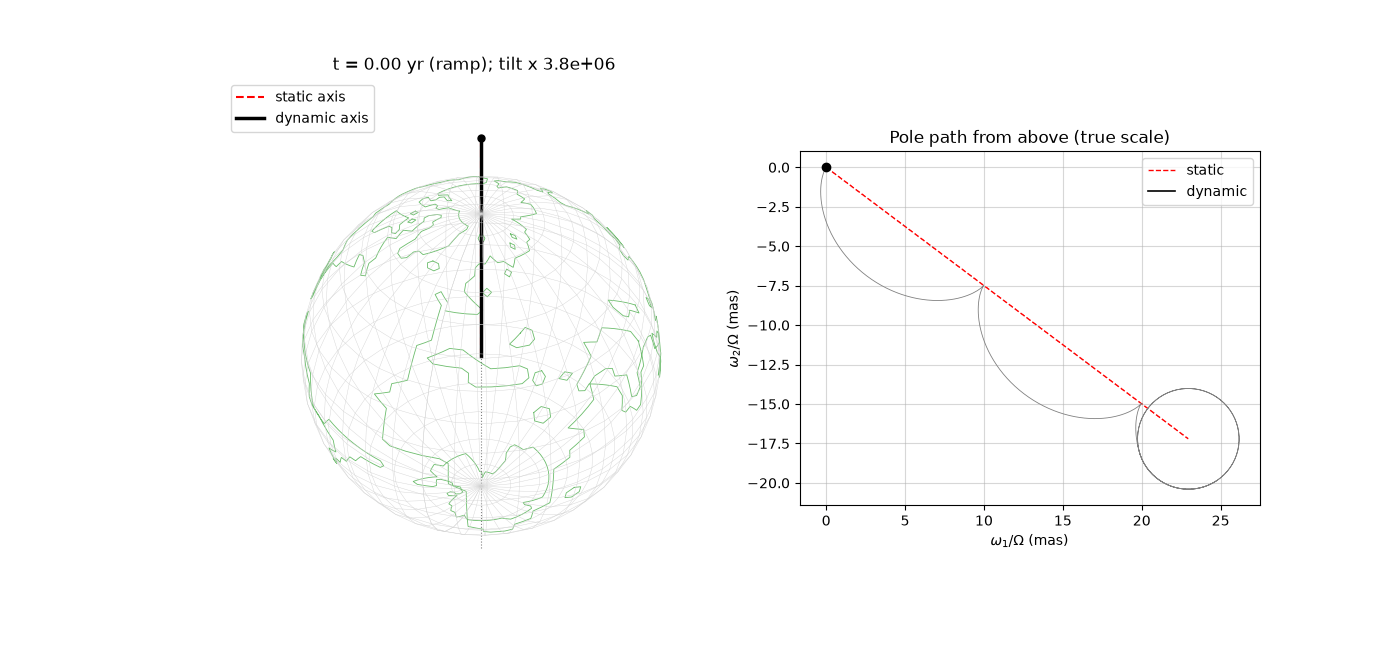

In [6]:
import os

os.makedirs(os.path.dirname(gif_path), exist_ok=True)
animation.save(gif_path, writer=PillowWriter(fps=frames_per_second))
print(f"saved {gif_path}")

Image(filename=gif_path)